### 1. Loading Data and Visualization Libraries

I will import Pandas for data manipulation, NumPy for numerical calculations, and Matplotlib for creating visualizations. I will then load the cleaned TMDb dataset and prepare the financial metrics required for plotting.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

data_path = PROJECT_ROOT / "data" / "processed" / "tmdb_movies_cleaned.csv"

df = pd.read_csv(data_path, parse_dates=["release_date"])

df["profit_musd"] = df["revenue_musd"] - df["budget_musd"]

df["roi"] = np.where(
    df["budget_musd"] > 0,
    df["revenue_musd"] / df["budget_musd"],
    np.nan
)

print("Dataset shape:", df.shape)

Dataset shape: (18, 24)


### 2. Revenue vs. Budget

A scatter plot will help investigate the relationship between production budgets and box-office revenues. Each point represents a movie. Movies above the reference line earn more revenue than their production budget, while movies below it earn less than their budget.

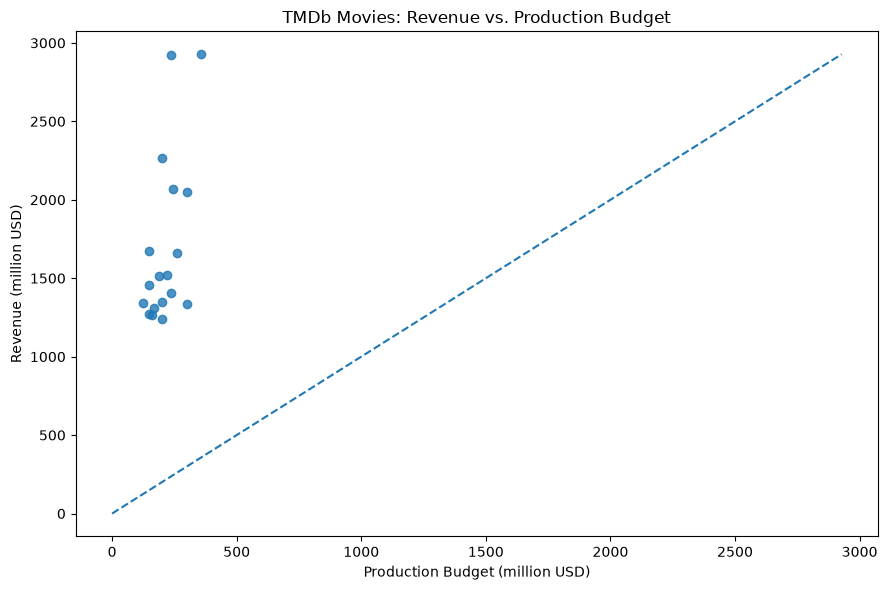

In [14]:
plot_df = df.dropna(subset=["budget_musd", "revenue_musd"])

plt.figure(figsize=(9, 6))
plt.scatter(
    plot_df["budget_musd"],
    plot_df["revenue_musd"],
    alpha=0.8
)

limit = max(
    plot_df["budget_musd"].max(),
    plot_df["revenue_musd"].max()
)

plt.plot([0, limit], [0, limit], linestyle="--")

plt.xlabel("Production Budget (million USD)")
plt.ylabel("Revenue (million USD)")
plt.title("TMDb Movies: Revenue vs. Production Budget")
plt.tight_layout()
figures_dir = PROJECT_ROOT / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(figures_dir / "revenue_vs_budget.png")
plt.show()

### 3. Return on Investment by Genre

Movies can belong to multiple genres. I will split the genre field so each movie contributes to every genre it belongs to, then calculate the median ROI for each genre among movies with budgets of at least $10 million. Median ROI helps reduce the influence of unusually large values.

In [3]:
roi_df = df[df["budget_musd"] >= 10].copy()

roi_df = roi_df.dropna(subset=["roi", "genres"])

roi_df["genres"] = roi_df["genres"].str.split(" | ", regex=False)

roi_df = roi_df.explode("genres")

genre_roi = (
    roi_df.groupby("genres")["roi"]
    .median()
    .sort_values(ascending=False)
)

display(genre_roi.to_frame("median_roi").round(2))

,median_roi
genres,
Comedy,9.69
Romance,9.62
Fantasy,9.09
Drama,8.86
Thriller,7.98
Crime,7.98
Family,7.91
Adventure,7.71
Animation,7.44


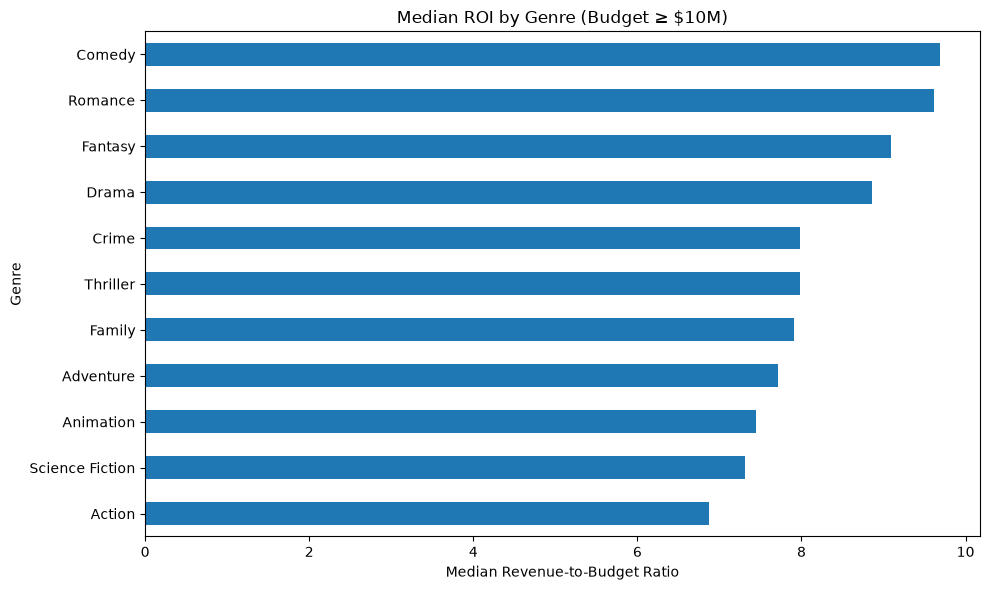

In [13]:
plt.figure(figsize=(10, 6))

genre_roi.sort_values().plot(kind="barh")

plt.xlabel("Median Revenue-to-Budget Ratio")
plt.ylabel("Genre")
plt.title("Median ROI by Genre (Budget ≥ $10M)")
plt.tight_layout()
figures_dir = PROJECT_ROOT / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(figures_dir / "median_roi_by_genre.png")
plt.show()

### 4. Popularity vs. Rating

I will use a scatter plot to examine whether movies with higher TMDb popularity also tend to receive higher audience ratings. This helps distinguish popularity from audience satisfaction.

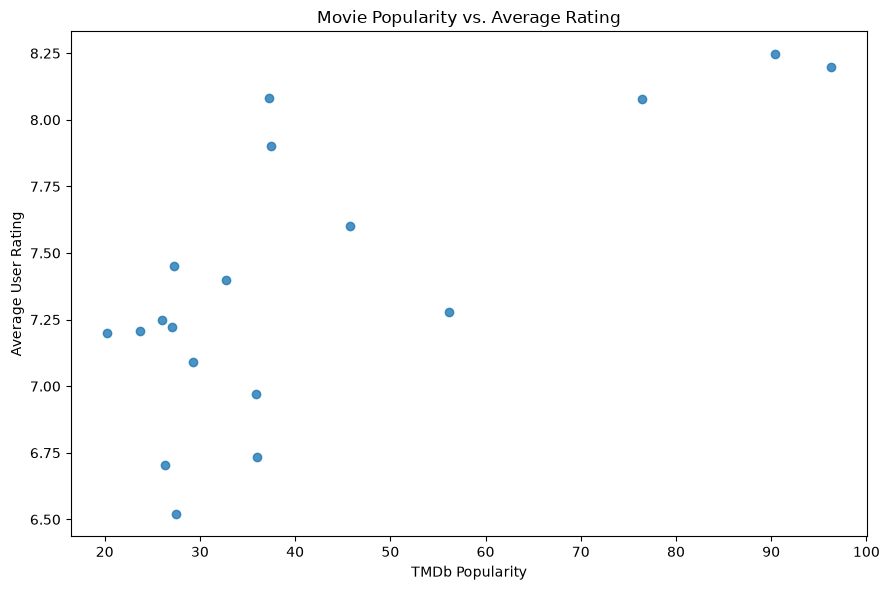

In [12]:
plot_df = df.dropna(subset=["popularity", "vote_average"])

plt.figure(figsize=(9, 6))
plt.scatter(
    plot_df["popularity"],
    plot_df["vote_average"],
    alpha=0.8
)

plt.xlabel("TMDb Popularity")
plt.ylabel("Average User Rating")
plt.title("Movie Popularity vs. Average Rating")
plt.tight_layout()
figures_dir = PROJECT_ROOT / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(figures_dir / "popularity_vs_rating.png")
plt.show()

### 5. Yearly Box-Office Trends

I will group movies by release year and calculate their combined revenue. This visualization will show the distribution of box-office revenue across the release years represented in the selected dataset.

In [6]:
df["release_year"] = df["release_date"].dt.year

yearly_revenue = (
    df.dropna(subset=["release_year", "revenue_musd"])
    .groupby("release_year")["revenue_musd"]
    .sum()
    .sort_index()
)

display(yearly_revenue.to_frame("total_revenue_musd").round(2))

,total_revenue_musd
release_year,
1997,2264.16
2009,2923.71
2011,1341.51
2012,1518.82
2013,1274.22
2015,6660.56
2017,2600.52
2018,5956.04
2019,6043.15


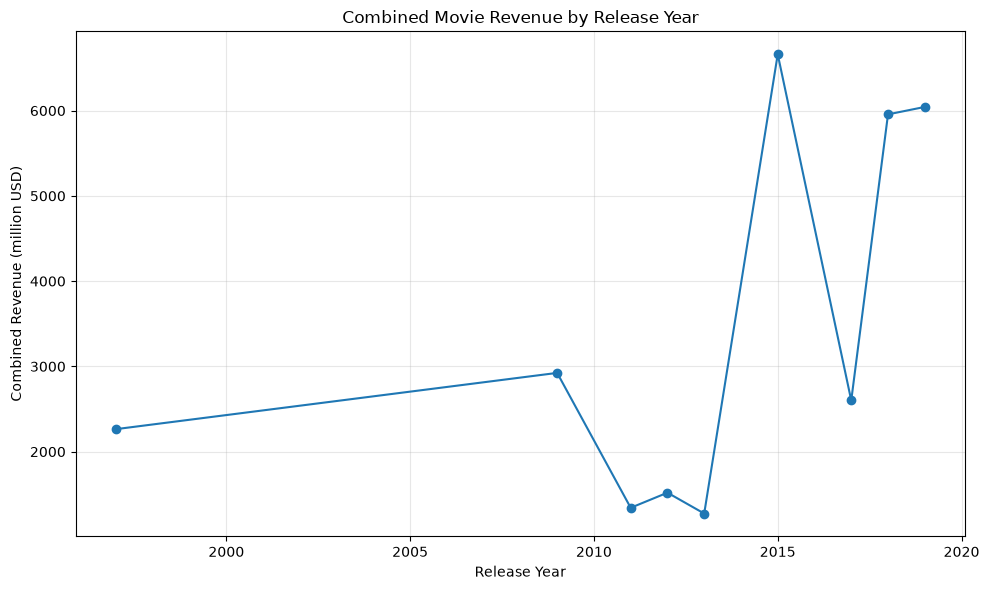

In [11]:
plt.figure(figsize=(10, 6))

plt.plot(
    yearly_revenue.index,
    yearly_revenue.values,
    marker="o"
)

plt.xlabel("Release Year")
plt.ylabel("Combined Revenue (million USD)")
plt.title("Combined Movie Revenue by Release Year")
plt.grid(True, alpha=0.3)
plt.tight_layout()
figures_dir = PROJECT_ROOT / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(figures_dir / "combined_revenue_by_release_year.png")
plt.show()

### 6. Franchise vs. Movies Without a Recorded Collection

I will compare movies with a recorded collection against movies without one. I will examine their mean revenue, median ROI, mean budget, mean popularity, and mean rating to identify differences between these groups.

In [8]:
df["movie_group"] = np.where(
    df["belongs_to_collection"].notna(),
    "Franchise",
    "No recorded collection"
)

comparison = (
    df.groupby("movie_group")
    .agg(
        mean_revenue_musd=("revenue_musd", "mean"),
        median_roi=("roi", "median"),
        mean_budget_musd=("budget_musd", "mean"),
        mean_popularity=("popularity", "mean"),
        mean_rating=("vote_average", "mean"),
        movie_count=("id", "count")
    )
)

display(comparison.round(2))

,mean_revenue_musd,median_roi,mean_budget_musd,mean_popularity,mean_rating,movie_count
movie_group,,,,,,
Franchise,1690.78,7.84,218.0,42.40,7.39,16
No recorded collection,1765.14,9.62,180.0,36.69,7.44,2


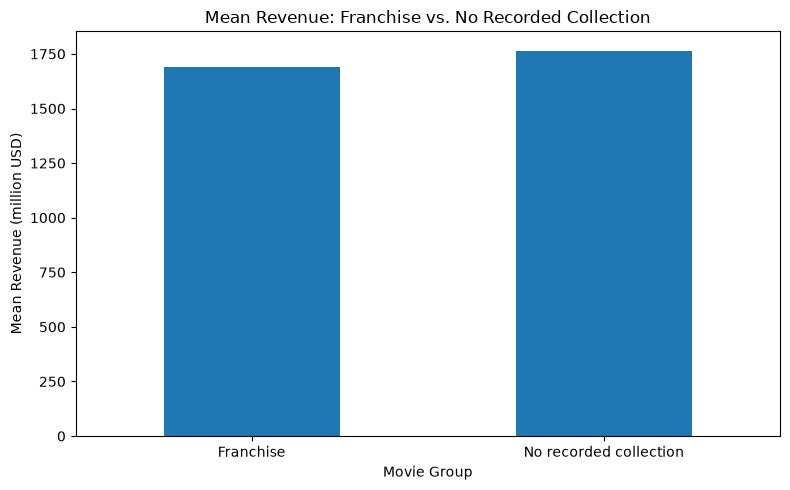

In [10]:
comparison["mean_revenue_musd"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.xlabel("Movie Group")
plt.ylabel("Mean Revenue (million USD)")
plt.title("Mean Revenue: Franchise vs. No Recorded Collection")
plt.xticks(rotation=0)
plt.tight_layout()
figures_dir = PROJECT_ROOT / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(figures_dir / "mean_revenue_by_movie_group.png")
plt.show()

### 7. Saving Visualizations

I will save the generated figures in the project's reports folder. These images can later be included in the final project report and README.